In [34]:
import datetime
import numpy as np

from util.log_handlers import read_current_log, read_temperature_log, read_voltage_log

In [45]:
import matplotlib.pyplot as plt

def plot_stage(t, y, x_label, y_label, title=None, st=None, ft=None):
    plt.figure(figsize=(9, 5))
    
    plt.plot(t, y, linewidth=2, color='#1f77b4', label=y_label)    
    plt.xlabel(x_label, fontsize=11, fontweight='bold', labelpad=10)
    plt.ylabel(y_label, fontsize=11, fontweight='bold', labelpad=10)
    
    if title:
        plt.title(title, fontsize=13, fontweight='bold', pad=15)

    if ft is not None or st is not None:
        st = t[0] if st is None else st
        ft = t[-1] if st is None else ft

    plt.xlim([st, ft])
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [46]:
path_to_log_temps = [
    "logs/temp/2026-10-11_18-48-38_temp/data.csv",
    "logs/temp/2026-10-15_09-09-43_temp/data.csv",
    "logs/temp/2026-10-16_20-16-04_temp/data.csv",
    "logs/temp/2026-10-17_00-48-50_temp/data.csv",
    "logs/temp/2026-10-17_10-21-13_temp/data.csv"
]

In [47]:
duration = datetime.timedelta(seconds=0)
temp_logs = []
for path in path_to_log_temps:
    times, temps = read_temperature_log(path)
    st = datetime.datetime.fromtimestamp(times[0])
    ft = datetime.datetime.fromtimestamp(times[-1])
    dt = ft - st
    duration += dt
    t_log = {"st": st, "ft": ft, "temp": temps}
    temp_logs.append(t_log)
    print(f"{st} - {ft}; длительность {dt}")
print(f"Полная длительность: {duration}")


2026-10-11 18:48:38.681970 - 2026-10-15 08:01:08.183364; длительность 3 days, 13:12:29.501394
2026-10-15 09:09:43.198269 - 2026-10-16 16:14:02.457306; длительность 1 day, 7:04:19.259037
2026-10-16 20:16:04.443680 - 2026-10-16 23:27:18.041438; длительность 3:11:13.597758
2026-10-17 00:48:50.301010 - 2026-10-17 01:32:04.927239; длительность 0:43:14.626229
2026-10-17 10:21:13.491060 - 2026-10-17 12:03:27.425769; длительность 1:42:13.934709
Полная длительность: 5 days, 1:53:30.919127


In [48]:
# реальная длительность записи
st, ft = temp_logs[0]["st"], temp_logs[0]["ft"]
dt_0 = ft - st

st, ft = temp_logs[1]["st"], temp_logs[1]["ft"]
dt_1 = ft - st
print((dt_0 + dt_1).total_seconds())

418608.760431


In [49]:
path_to_log_voltages = [
    "logs/voltage/2026-10-11_18-46-27_voltage/data.csv",
    "logs/voltage/2026-10-12_09-55-33_voltage/data.csv",
    "logs/voltage/2026-10-16_20-14-47_voltage/data.csv",
    "logs/voltage/2026-10-16_20-16-43_voltage/data.csv",
]

In [50]:
duration = datetime.timedelta(seconds=0)
voltage_logs = []
for path in path_to_log_voltages:
    times, voltages = read_voltage_log(path)
    st = datetime.datetime.fromtimestamp(times[0])
    ft = datetime.datetime.fromtimestamp(times[-1])
    dt = ft - st
    duration += dt
    v_log = {"st": st, "ft": ft, "voltage": voltages}
    voltage_logs.append(v_log)
    print(f"{st} - {ft}; длительность {dt}")
print(f"Полная длительность: {duration}")


2026-10-11 18:46:27.346000 - 2026-10-12 09:54:30.753000; длительность 15:08:03.407000
2026-10-12 09:55:35.131000 - 2026-10-16 20:10:09.724000; длительность 4 days, 10:14:34.593000
2026-10-16 20:14:47.383000 - 2026-10-16 20:16:16.035000; длительность 0:01:28.652000
2026-10-16 20:16:43.426000 - 2026-10-17 23:22:41.139000; длительность 1 day, 3:05:57.713000
Полная длительность: 6 days, 4:30:04.365000


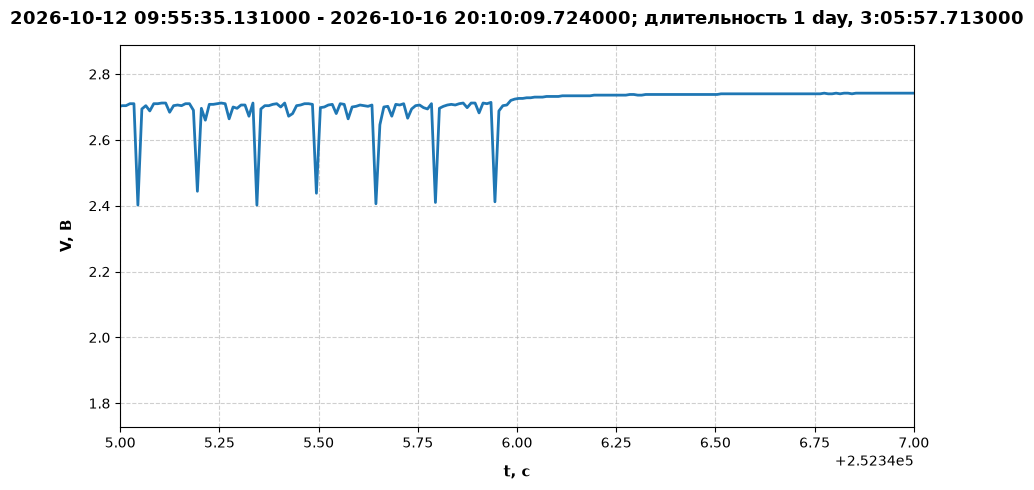

In [72]:
# графики напряжения
idx = 1
st, ft, v = voltage_logs[idx]["st"], voltage_logs[idx]["ft"], voltage_logs[idx]["voltage"]
times = np.linspace(st.timestamp(), ft.timestamp(), len(v)) - st.timestamp()
title = f"{st} - {ft}; длительность {dt}"
plot_stage(t=times, y=v, title=title, x_label="t, c", y_label="V, В", st=252345, ft=252347)

In [42]:
path_to_log_currents = [
    "logs/current/ppk-20261015T060642.csv",
    "logs/current/ppk-20261015T155100.csv",
    "logs/current/ppk-20261016T063902.csv",
    "logs/current/ppk-20261016T170714.csv",
    "logs/current/ppk-20261016T222013.csv",
    "logs/current/ppk-20261017T202228.csv",
]

In [43]:
duration = datetime.timedelta(seconds=0)
current_logs = []
for path in path_to_log_currents:
    times, current = read_current_log(path)
    st = datetime.datetime.fromtimestamp(times[0])
    ft = datetime.datetime.fromtimestamp(times[-1])
    dt = ft - st
    duration += dt
    c_log = {"st": st, "ft": ft, "current": current}
    current_logs.append(c_log)
    print(f"{st} - {ft}; длительность {dt}")
print(f"Полная длительность: {duration}")

2026-10-15 09:06:42 - 2026-10-16 01:25:01.990000; длительность 16:18:19.990000
2026-10-15 18:51:00 - 2026-10-15 21:57:39.990000; длительность 3:06:39.990000
2026-10-16 09:39:02 - 2026-10-17 00:26:32.550000; длительность 14:47:30.550000
2026-10-16 20:07:14 - 2026-10-17 06:34:50.130000; длительность 10:27:36.130000
2026-10-17 01:20:13 - 2026-10-17 06:26:40.800000; длительность 5:06:27.800000
2026-10-17 23:22:28 - 2026-10-18 21:24:18.940000; длительность 22:01:50.940000
Полная длительность: 2 days, 23:48:25.400000


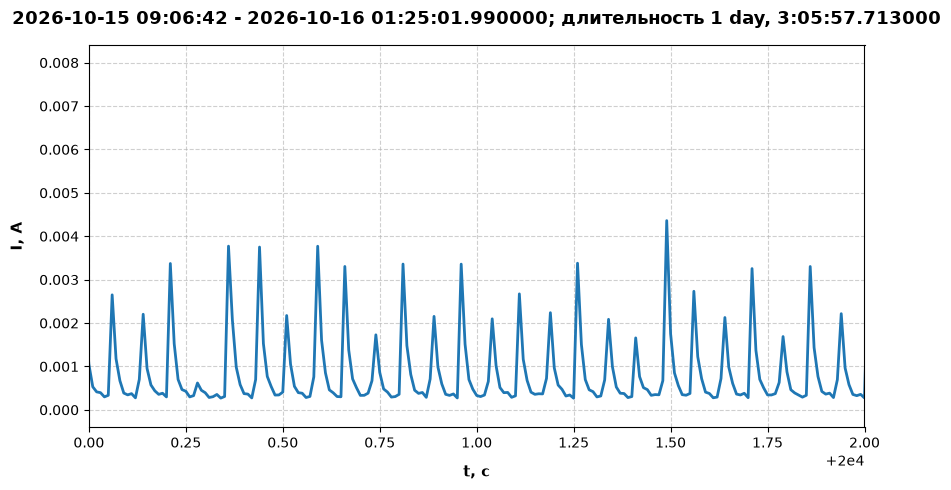

In [78]:
# графики тока
idx = 0
st, ft, i = current_logs[idx]["st"], current_logs[idx]["ft"], current_logs[idx]["current"]
times = np.linspace(st.timestamp(), ft.timestamp(), len(v)) - st.timestamp()
title = f"{st} - {ft}; длительность {dt}"
plot_stage(t=times, y=i, title=title, x_label="t, c", y_label="I, А", st=20000, ft=20002)

In [76]:
np.average(i) * 1000_000 # in uV

np.float64(842.8725229664394)